In [2]:
%pip install pandas


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

speeches = pd.read_csv("../data/twelfth_night_speeches.csv")

speeches.head()

,act,scene,speaker,lines,text,clean_text
0,1,1,ORSINO,15,"If music be the food of love, play on.\nGive m...",music food love play give excess surfeit appet...
1,1,1,CURIO,1,"Will you go hunt, my lord?",go hunt lord
2,1,1,ORSINO,1,"What, Curio?",curio
3,1,1,CURIO,1,The hart.,hart
4,1,1,ORSINO,7,"Why, so I do, the noblest that I have.\nO, whe...",noble mine eye see olivia first methought purg...


In [4]:
print("Total speeches:", len(speeches))
print("Number of characters:", speeches["speaker"].nunique())
print("Characters:")
print(sorted(speeches["speaker"].unique()))

Total speeches: 926
Number of characters: 18
Characters:
['ANDREW', 'ANTONIO', 'CAPTAIN', 'CURIO', 'FABIAN', 'FIRST OFFICER', 'FOOL', 'MALVOLIO', 'MARIA', 'OLIVIA', 'ORSINO', 'PRIEST', 'SEBASTIAN', 'SECOND OFFICER', 'SERVANT', 'TOBY', 'VALENTINE', 'VIOLA']


In [5]:
speeches["next_speaker"] = speeches.groupby(
    ["act", "scene"]
)["speaker"].shift(-1)

transitions = speeches.dropna(
    subset=["next_speaker"]
)[["act", "scene", "speaker", "next_speaker"]]

transitions.head(10)

,act,scene,speaker,next_speaker
0,1,1,ORSINO,CURIO
1,1,1,CURIO,ORSINO
2,1,1,ORSINO,CURIO
3,1,1,CURIO,ORSINO
4,1,1,ORSINO,VALENTINE
5,1,1,VALENTINE,ORSINO
7,1,2,VIOLA,CAPTAIN
8,1,2,CAPTAIN,VIOLA
9,1,2,VIOLA,CAPTAIN
10,1,2,CAPTAIN,VIOLA


In [6]:
transition_counts = (
    transitions.groupby(["speaker", "next_speaker"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

transition_counts.head(15)

,speaker,next_speaker,count
8,ANDREW,TOBY,47
83,TOBY,ANDREW,47
100,VIOLA,OLIVIA,44
63,OLIVIA,VIOLA,40
85,TOBY,FABIAN,27
25,FABIAN,TOBY,24
32,FOOL,MALVOLIO,24
43,MALVOLIO,OLIVIA,24
51,MARIA,TOBY,24
56,OLIVIA,MALVOLIO,23


In [7]:
%pip install networkx matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a directed network
G = nx.DiGraph()

# Add connections between characters
for _, row in transition_counts.iterrows():
    G.add_edge(
        row["speaker"],
        row["next_speaker"],
        weight=row["count"]
    )

print("Number of characters:", G.number_of_nodes())
print("Number of connections:", G.number_of_edges())

Number of characters: 18
Number of connections: 105


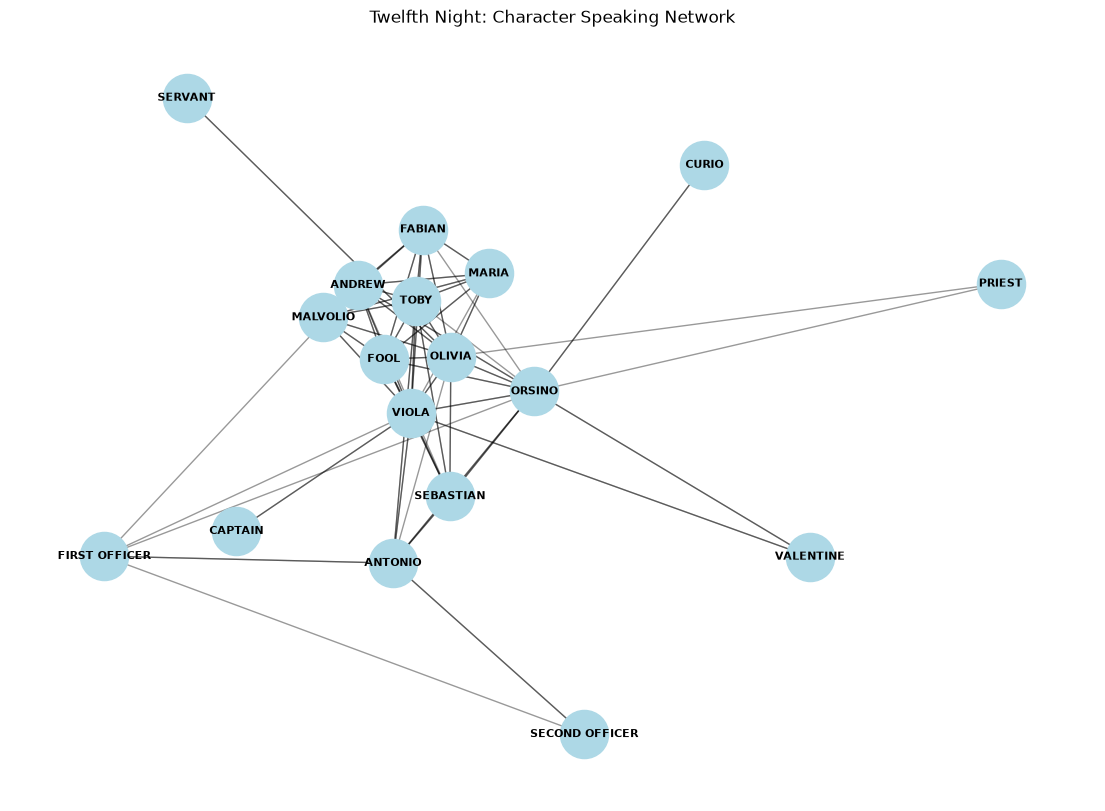

In [9]:
plt.figure(figsize=(14, 10))

# Position the characters around the graph
pos = nx.spring_layout(G, seed=42, k=1.5)

# Draw character nodes
nx.draw_networkx_nodes(
    G, pos,
    node_size=1200,
    node_color="lightblue"
)

# Draw connections
nx.draw_networkx_edges(
    G, pos,
    width=1,
    alpha=0.4,
    arrows=True,
    arrowsize=15
)

# Add character names
nx.draw_networkx_labels(
    G, pos,
    font_size=8,
    font_weight="bold"
)

plt.title("Twelfth Night: Character Speaking Network")
plt.axis("off")
plt.show()

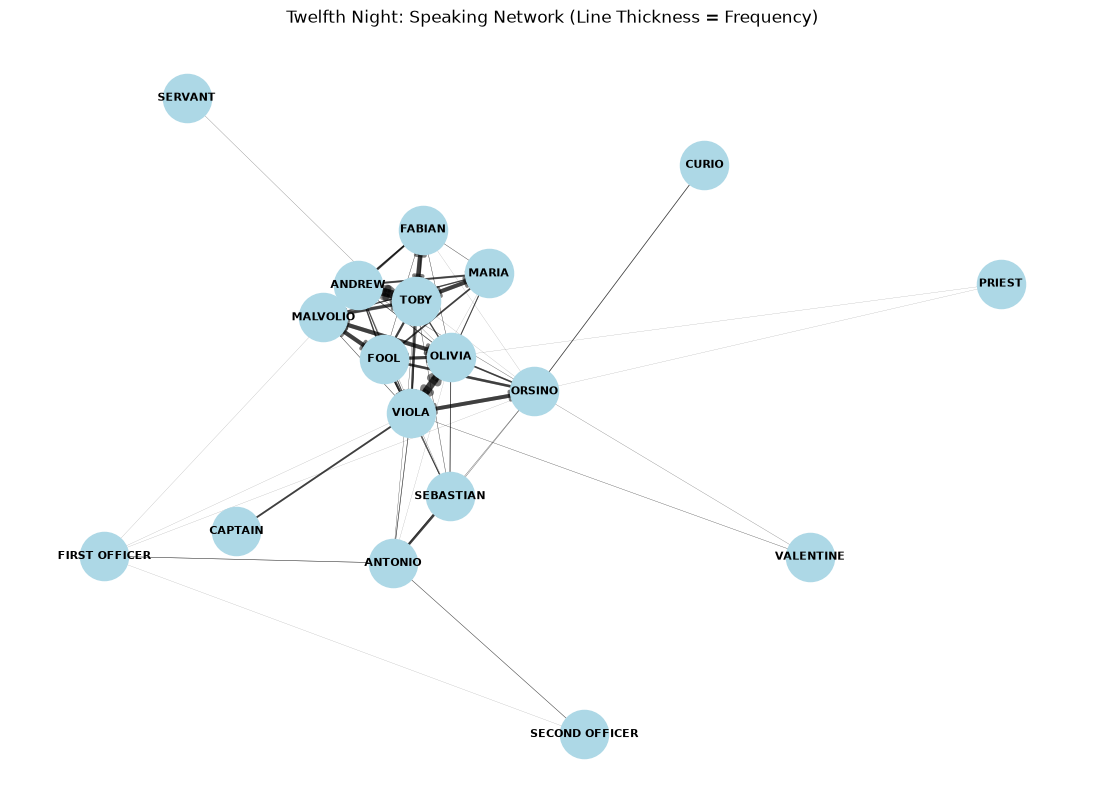

In [10]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42, k=1.5)

# Make stronger connections thicker
edge_widths = [
    G[u][v]["weight"] / 8
    for u, v in G.edges()
]

nx.draw_networkx_nodes(
    G, pos,
    node_size=1200,
    node_color="lightblue"
)

nx.draw_networkx_edges(
    G, pos,
    width=edge_widths,
    alpha=0.5,
    arrows=True,
    arrowsize=15
)

nx.draw_networkx_labels(
    G, pos,
    font_size=8,
    font_weight="bold"
)

plt.title("Twelfth Night: Speaking Network (Line Thickness = Frequency)")
plt.axis("off")
plt.show()

In [11]:
transitions_per_act = (
    transitions.groupby("act")
    .size()
    .reset_index(name="number_of_transitions")
)

transitions_per_act

,act,number_of_transitions
0,1,223
1,2,219
2,3,259
3,4,81
4,5,126


In [12]:
speeches_per_act = (
    speeches.groupby("act")
    .size()
    .reset_index(name="number_of_speeches")
)

speeches_per_act

,act,number_of_speeches
0,1,228
1,2,224
2,3,263
3,4,84
4,5,127


In [13]:
unique_pairs_per_act = (
    transitions.groupby("act")
    .apply(
        lambda group: group[
            ["speaker", "next_speaker"]
        ].drop_duplicates().shape[0]
    )
    .reset_index(name="unique_speaking_pairs")
)

unique_pairs_per_act

,act,unique_speaking_pairs
0,1,32
1,2,34
2,3,46
3,4,20
4,5,45


In [14]:
characters_per_act = (
    speeches.groupby("act")["speaker"]
    .nunique()
    .reset_index(name="number_of_characters")
)

characters_per_act

,act,number_of_characters
0,1,11
1,2,11
2,3,13
3,4,7
4,5,12


In [15]:
relationship_density = unique_pairs_per_act.merge(
    characters_per_act, on="act"
)

relationship_density["possible_pairs"] = (
    relationship_density["number_of_characters"]
    * (relationship_density["number_of_characters"] - 1)
)

relationship_density["density"] = (
    relationship_density["unique_speaking_pairs"]
    / relationship_density["possible_pairs"]
)

relationship_density

,act,unique_speaking_pairs,number_of_characters,possible_pairs,density
0,1,32,11,110,0.290909
1,2,34,11,110,0.309091
2,3,46,13,156,0.294872
3,4,20,7,42,0.476190
4,5,45,12,132,0.340909


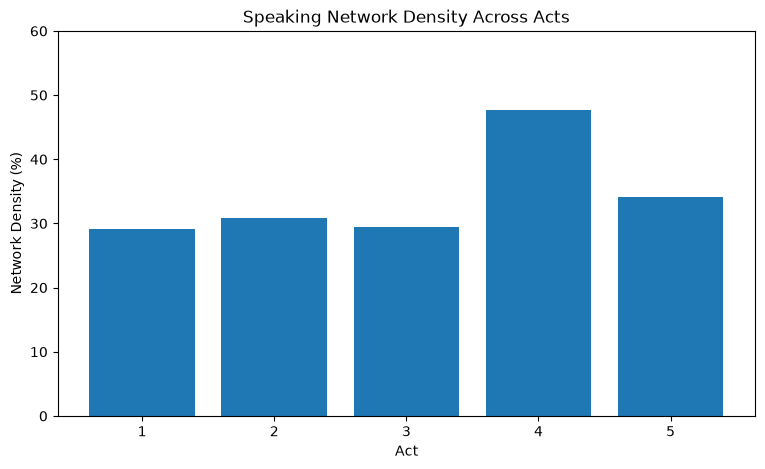

In [16]:
plt.figure(figsize=(9, 5))

plt.bar(
    relationship_density["act"],
    relationship_density["density"] * 100
)

plt.title("Speaking Network Density Across Acts")
plt.xlabel("Act")
plt.ylabel("Network Density (%)")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 60)

plt.show()

In [17]:
# Select only speeches from Act 1
act1_transitions = transitions[
    transitions["act"] == 1
]

# Count speaking transitions
act1_counts = (
    act1_transitions.groupby(["speaker", "next_speaker"])
    .size()
    .reset_index(name="count")
)

# Create the Act 1 network
G1 = nx.DiGraph()

for _, row in act1_counts.iterrows():
    G1.add_edge(
        row["speaker"],
        row["next_speaker"],
        weight=row["count"]
    )

print("Act 1 characters:", G1.number_of_nodes())
print("Act 1 connections:", G1.number_of_edges())

Act 1 characters: 11
Act 1 connections: 32


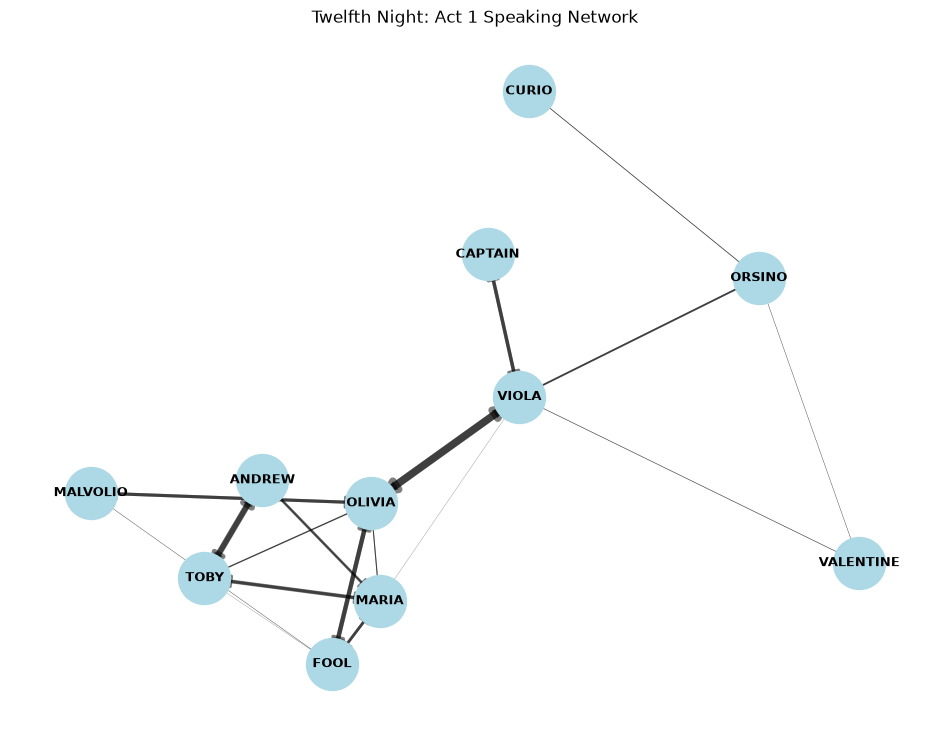

In [18]:
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G1, seed=42, k=1.5)

edge_widths = [
    G1[u][v]["weight"] / 4
    for u, v in G1.edges()
]

nx.draw_networkx_nodes(
    G1, pos,
    node_size=1400,
    node_color="lightblue"
)

nx.draw_networkx_edges(
    G1, pos,
    width=edge_widths,
    alpha=0.5,
    arrows=True,
    arrowsize=18
)

nx.draw_networkx_labels(
    G1, pos,
    font_size=9,
    font_weight="bold"
)

plt.title("Twelfth Night: Act 1 Speaking Network")
plt.axis("off")
plt.show()

In [19]:
act2_transitions = transitions[
    transitions["act"] == 2
]

act2_counts = (
    act2_transitions.groupby(["speaker", "next_speaker"])
    .size()
    .reset_index(name="count")
)

G2 = nx.DiGraph()

for _, row in act2_counts.iterrows():
    G2.add_edge(
        row["speaker"],
        row["next_speaker"],
        weight=row["count"]
    )

print("Act 2 characters:", G2.number_of_nodes())
print("Act 2 connections:", G2.number_of_edges())

Act 2 characters: 11
Act 2 connections: 34


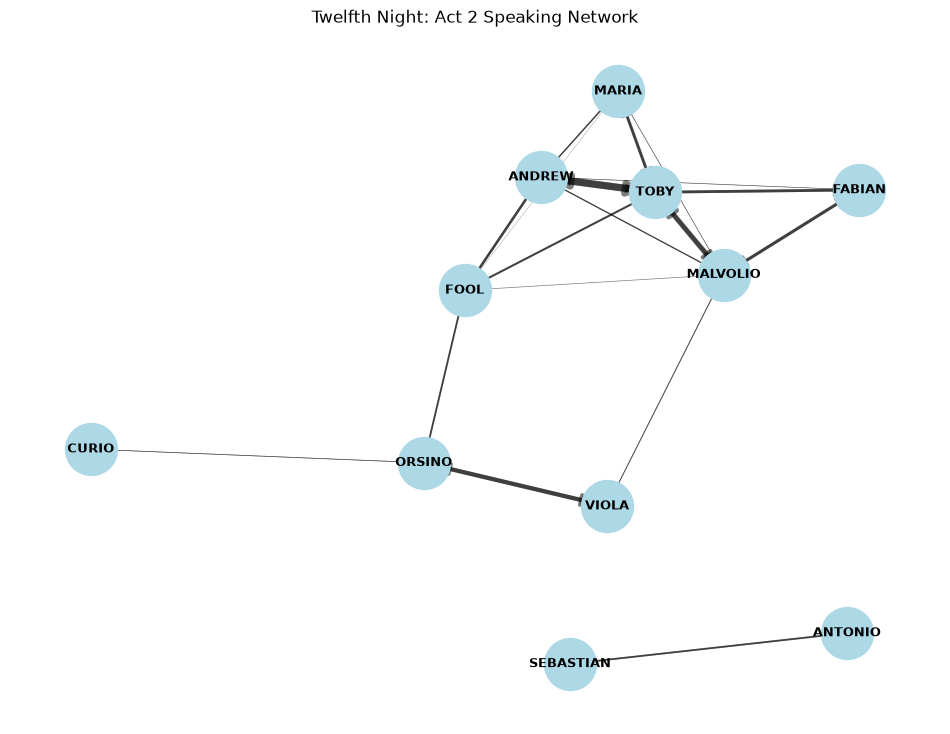

In [20]:
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G2, seed=42, k=1.5)

edge_widths = [
    G2[u][v]["weight"] / 4
    for u, v in G2.edges()
]

nx.draw_networkx_nodes(
    G2, pos,
    node_size=1400,
    node_color="lightblue"
)

nx.draw_networkx_edges(
    G2, pos,
    width=edge_widths,
    alpha=0.5,
    arrows=True,
    arrowsize=18
)

nx.draw_networkx_labels(
    G2, pos,
    font_size=9,
    font_weight="bold"
)

plt.title("Twelfth Night: Act 2 Speaking Network")
plt.axis("off")
plt.show()

In [21]:
act3_transitions = transitions[
    transitions["act"] == 3
]

act3_counts = (
    act3_transitions.groupby(["speaker", "next_speaker"])
    .size()
    .reset_index(name="count")
)

G3 = nx.DiGraph()

for _, row in act3_counts.iterrows():
    G3.add_edge(
        row["speaker"],
        row["next_speaker"],
        weight=row["count"]
    )

print("Act 3 characters:", G3.number_of_nodes())
print("Act 3 connections:", G3.number_of_edges())

Act 3 characters: 13
Act 3 connections: 46


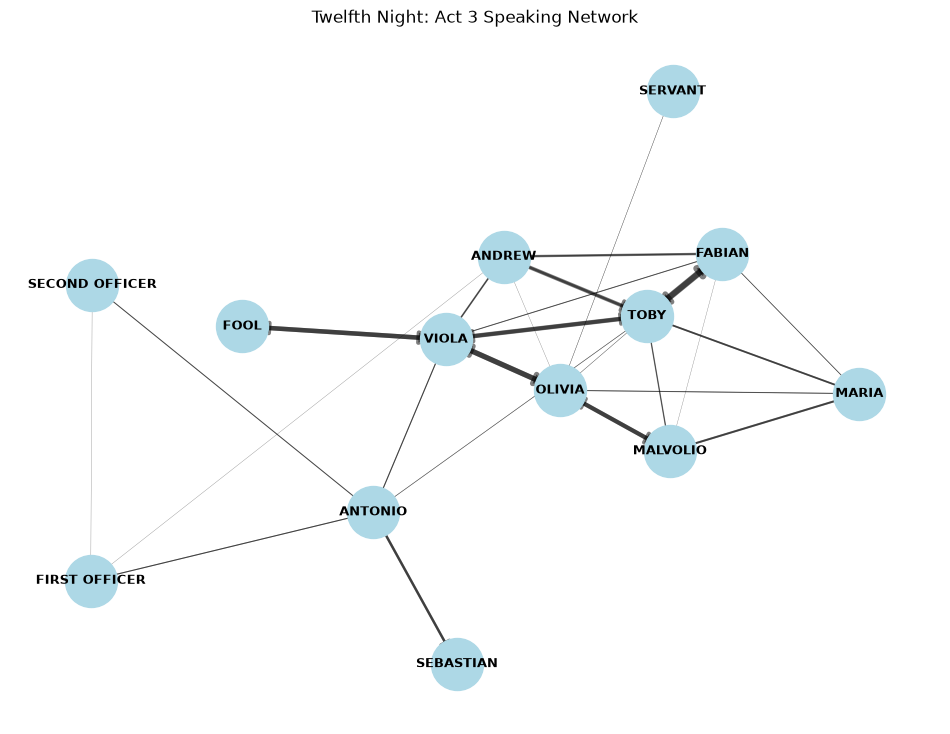

In [22]:
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G3, seed=42, k=1.5)

edge_widths = [
    G3[u][v]["weight"] / 4
    for u, v in G3.edges()
]

nx.draw_networkx_nodes(
    G3, pos,
    node_size=1400,
    node_color="lightblue"
)

nx.draw_networkx_edges(
    G3, pos,
    width=edge_widths,
    alpha=0.5,
    arrows=True,
    arrowsize=18
)

nx.draw_networkx_labels(
    G3, pos,
    font_size=9,
    font_weight="bold"
)

plt.title("Twelfth Night: Act 3 Speaking Network")
plt.axis("off")
plt.show()

In [23]:
act4_transitions = transitions[
    transitions["act"] == 4
]

act4_counts = (
    act4_transitions.groupby(["speaker", "next_speaker"])
    .size()
    .reset_index(name="count")
)

G4 = nx.DiGraph()

for _, row in act4_counts.iterrows():
    G4.add_edge(
        row["speaker"],
        row["next_speaker"],
        weight=row["count"]
    )

print("Act 4 characters:", G4.number_of_nodes())
print("Act 4 connections:", G4.number_of_edges())

Act 4 characters: 7
Act 4 connections: 20


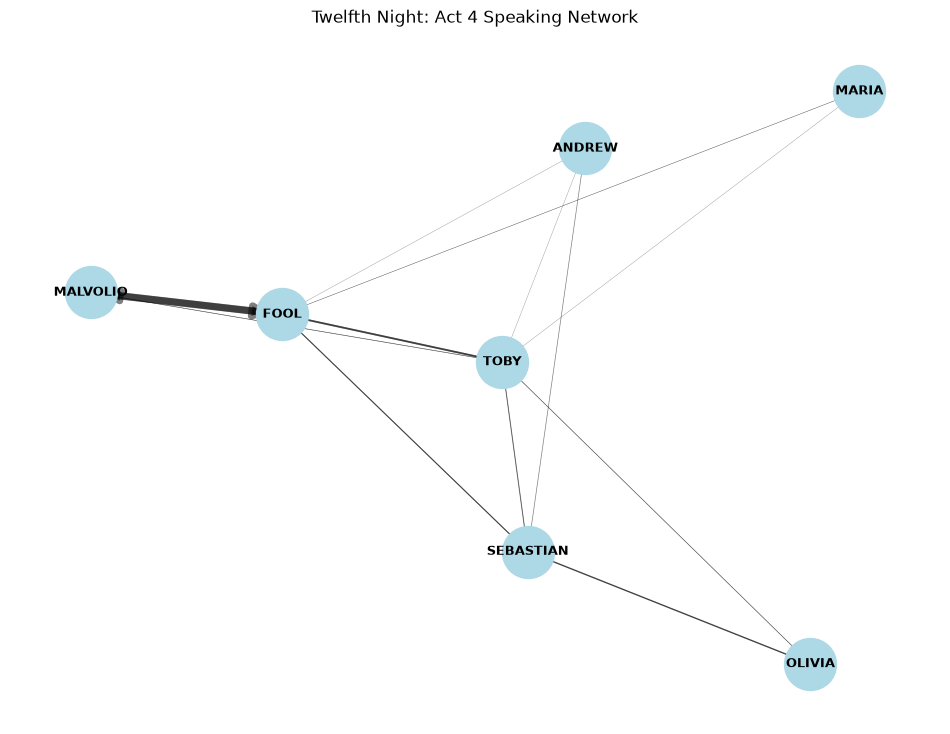

In [24]:
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G4, seed=42, k=1.5)

edge_widths = [
    G4[u][v]["weight"] / 4
    for u, v in G4.edges()
]

nx.draw_networkx_nodes(
    G4, pos,
    node_size=1400,
    node_color="lightblue"
)

nx.draw_networkx_edges(
    G4, pos,
    width=edge_widths,
    alpha=0.5,
    arrows=True,
    arrowsize=18
)

nx.draw_networkx_labels(
    G4, pos,
    font_size=9,
    font_weight="bold"
)

plt.title("Twelfth Night: Act 4 Speaking Network")
plt.axis("off")
plt.show()

In [25]:
act5_transitions = transitions[
    transitions["act"] == 5
]

act5_counts = (
    act5_transitions.groupby(["speaker", "next_speaker"])
    .size()
    .reset_index(name="count")
)

G5 = nx.DiGraph()

for _, row in act5_counts.iterrows():
    G5.add_edge(
        row["speaker"],
        row["next_speaker"],
        weight=row["count"]
    )

print("Act 5 characters:", G5.number_of_nodes())
print("Act 5 connections:", G5.number_of_edges())

Act 5 characters: 12
Act 5 connections: 45


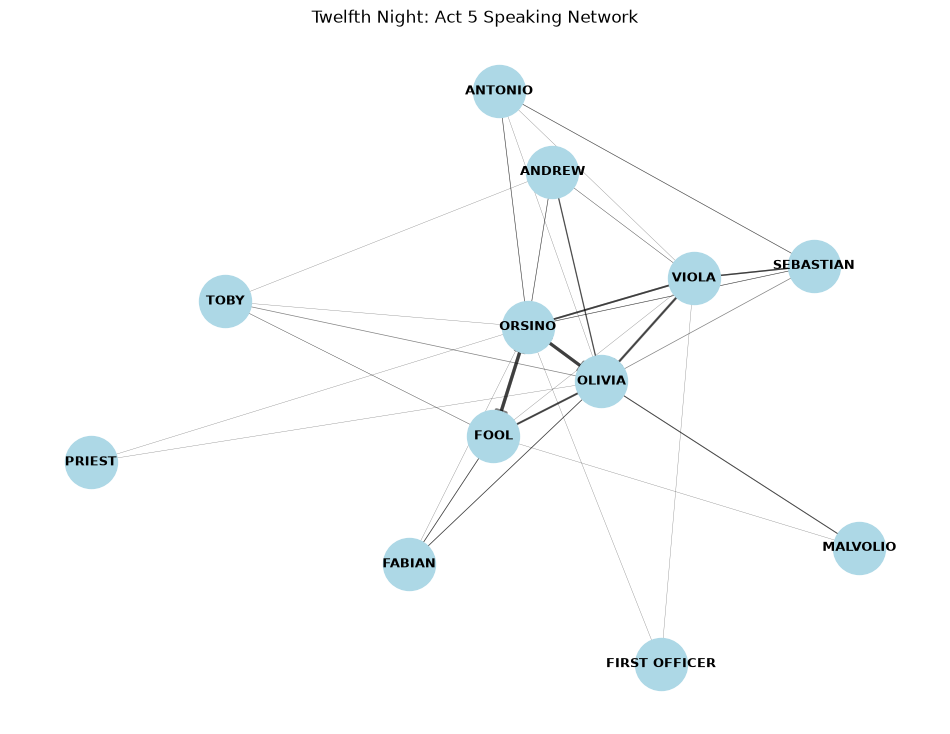

In [26]:
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G5, seed=42, k=1.5)

edge_widths = [
    G5[u][v]["weight"] / 4
    for u, v in G5.edges()
]

nx.draw_networkx_nodes(
    G5, pos,
    node_size=1400,
    node_color="lightblue"
)

nx.draw_networkx_edges(
    G5, pos,
    width=edge_widths,
    alpha=0.5,
    arrows=True,
    arrowsize=18
)

nx.draw_networkx_labels(
    G5, pos,
    font_size=9,
    font_weight="bold"
)

plt.title("Twelfth Night: Act 5 Speaking Network")
plt.axis("off")
plt.show()

In [27]:
act_summary = pd.DataFrame({
    "Act": [1, 2, 3, 4, 5],
    "Characters": [11, 11, 13, 7, 12],
    "Unique Speaking Connections": [32, 34, 46, 20, 45],
    "Network Density (%)": [29.1, 30.9, 29.5, 47.6, 34.1]
})

display(act_summary)

,Act,Characters,Unique Speaking Connections,Network Density (%)
0,1,11,32,29.1
1,2,11,34,30.9
2,3,13,46,29.5
3,4,7,20,47.6
4,5,12,45,34.1


In [28]:
dialogue_examples = speeches.copy()

dialogue_examples["next_speaker"] = (
    dialogue_examples.groupby(["act", "scene"])["speaker"].shift(-1)
)

dialogue_examples["next_text"] = (
    dialogue_examples.groupby(["act", "scene"])["text"].shift(-1)
)

dialogue_examples[
    ["act", "scene", "speaker", "text", "next_speaker", "next_text"]
].head(5)

,act,scene,speaker,text,next_speaker,next_text
0,1,1,ORSINO,"If music be the food of love, play on.\nGive m...",CURIO,"Will you go hunt, my lord?"
1,1,1,CURIO,"Will you go hunt, my lord?",ORSINO,"What, Curio?"
2,1,1,ORSINO,"What, Curio?",CURIO,The hart.
3,1,1,CURIO,The hart.,ORSINO,"Why, so I do, the noblest that I have.\nO, whe..."
4,1,1,ORSINO,"Why, so I do, the noblest that I have.\nO, whe...",VALENTINE,"So please my lord, I might not be admitted,\nB..."


In [29]:
viola_olivia = dialogue_examples[
    (dialogue_examples["speaker"] == "VIOLA") &
    (dialogue_examples["next_speaker"] == "OLIVIA")
]

viola_olivia[
    ["act", "scene", "text", "next_text"]
]

,act,scene,text,next_text
179,1,5,"The honorable lady of the house, which is she?",Speak to me. I shall answer for her. Your will?
181,1,5,"Most radiant, exquisite, and unmatchable\nbeau...","Whence came you, sir?"
183,1,5,"I can say little more than I have studied, and...",Are you a comedian?
185,1,5,"No, my profound heart. And yet by the very\nfa...","If I do not usurp myself, I am."
187,1,5,"Most certain, if you are she, you do usurp\nyo...",Come to what is important in 't. I forgive you...
189,1,5,"Alas, I took great pains to study it, and 'tis...","It is the more like to be feigned. I pray you,..."
192,1,5,"No, good swabber, I am to hull here a little\n...",Tell me your mind.
194,1,5,I am a messenger.,Sure you have some hideous matter to deliver\n...
196,1,5,It alone concerns your ear. I bring no overtur...,Yet you began rudely. What are you? What\nwoul...
198,1,5,The rudeness that hath appeared in me have I\n...,Give us the place alone. We will hear this\ndi...


In [30]:
olivia_viola = dialogue_examples[
    (dialogue_examples["speaker"] == "OLIVIA") &
    (dialogue_examples["next_speaker"] == "VIOLA")
]

olivia_viola[
    ["act", "scene", "text", "next_text"]
]

,act,scene,text,next_text
178,1,5,"Give me my veil. Come, throw it o'er my face.\...","The honorable lady of the house, which is she?"
180,1,5,Speak to me. I shall answer for her. Your will?,"Most radiant, exquisite, and unmatchable\nbeau..."
182,1,5,"Whence came you, sir?","I can say little more than I have studied, and..."
184,1,5,Are you a comedian?,"No, my profound heart. And yet by the very\nfa..."
186,1,5,"If I do not usurp myself, I am.","Most certain, if you are she, you do usurp\nyo..."
188,1,5,Come to what is important in 't. I forgive you...,"Alas, I took great pains to study it, and 'tis..."
193,1,5,Tell me your mind.,I am a messenger.
195,1,5,Sure you have some hideous matter to deliver\n...,It alone concerns your ear. I bring no overtur...
197,1,5,Yet you began rudely. What are you? What\nwoul...,The rudeness that hath appeared in me have I\n...
199,1,5,Give us the place alone. We will hear this\ndi...,Most sweet lady--


In [31]:
viola_olivia_counts = (
    transitions[
        (
            (transitions["speaker"] == "VIOLA") &
            (transitions["next_speaker"] == "OLIVIA")
        ) |
        (
            (transitions["speaker"] == "OLIVIA") &
            (transitions["next_speaker"] == "VIOLA")
        )
    ]
    .groupby(["act", "speaker"])
    .size()
    .unstack(fill_value=0)
)

viola_olivia_counts

speaker,OLIVIA,VIOLA
act,,
1,21,22
3,15,15
5,4,7


In [32]:
for act in [1, 3, 5]:
    print(f"\n--- ACT {act}: VIOLA ---")

    exchanges = viola_olivia[
        viola_olivia["act"] == act
    ]

    for _, row in exchanges.iterrows():
        print(row["text"])
        print()


--- ACT 1: VIOLA ---
The honorable lady of the house, which is she?

Most radiant, exquisite, and unmatchable
beauty--I pray you, tell me if this be the lady of the
house, for I never saw her. I would be loath to cast
away my speech, for, besides that it is excellently
well penned, I have taken great pains to con it. Good
beauties, let me sustain no scorn. I am very comptible
even to the least sinister usage.

I can say little more than I have studied, and
that question's out of my part. Good gentle one,
give me modest assurance if you be the lady of the
house, that I may proceed in my speech.

No, my profound heart. And yet by the very
fangs of malice I swear I am not that I play. Are
you the lady of the house?

Most certain, if you are she, you do usurp
yourself, for what is yours to bestow is not yours to
reserve. But this is from my commission. I will on
with my speech in your praise and then show you
the heart of my message.

Alas, I took great pains to study it, and 'tis
poetica

In [33]:
for act in [1, 3, 5]:
    print(f"\n--- ACT {act}: OLIVIA ---")

    exchanges = olivia_viola[
        olivia_viola["act"] == act
    ]

    for _, row in exchanges.iterrows():
        print(row["text"])
        print()


--- ACT 1: OLIVIA ---
Give me my veil. Come, throw it o'er my face.
We'll once more hear Orsino's embassy.

Speak to me. I shall answer for her. Your will?

Whence came you, sir?

Are you a comedian?

If I do not usurp myself, I am.

Come to what is important in 't. I forgive you
the praise.

Tell me your mind.

Sure you have some hideous matter to deliver
when the courtesy of it is so fearful. Speak your
office.

Yet you began rudely. What are you? What
would you?

Give us the place alone. We will hear this
divinity. Now, sir, what
is your text?

A comfortable doctrine, and much may be said
of it. Where lies your text?

In his bosom? In what chapter of his bosom?

O, I have read it; it is heresy. Have you no more
to say?

Have you any commission from your lord to
negotiate with my face? You are now out of your
text. But we will draw the curtain and show you the
picture. Look you, sir, such a
one I was this present. Is 't not well done?

'Tis in grain, sir; 'twill endure wind and
weat

In [34]:
import re

keywords = [
    "love", "heart", "affection",
    "identity", "disguise", "name", "myself",
    "beauty", "sweet", "desire",
    "hate", "cannot", "scorn", "beguiled"
]

pair_dialogue = dialogue_examples[
    (
        (dialogue_examples["speaker"] == "VIOLA") &
        (dialogue_examples["next_speaker"] == "OLIVIA")
    ) |
    (
        (dialogue_examples["speaker"] == "OLIVIA") &
        (dialogue_examples["next_speaker"] == "VIOLA")
    )
].copy()

print("Total dialogue turns:", len(pair_dialogue))
print("Acts represented:", sorted(pair_dialogue["act"].unique()))

Total dialogue turns: 84
Acts represented: [np.int64(1), np.int64(3), np.int64(5)]


In [35]:
keyword_counts = []

for keyword in keywords:
    count = pair_dialogue["text"].str.lower().apply(
        lambda text: len(re.findall(r"\b" + keyword + r"\b", str(text)))
    ).sum()

    keyword_counts.append({
        "Keyword": keyword,
        "Occurrences": count
    })

keyword_results = pd.DataFrame(keyword_counts)

keyword_results.sort_values(
    "Occurrences",
    ascending=False
)

,Keyword,Occurrences
0,love,20
1,heart,8
7,beauty,4
5,name,3
6,myself,3
8,sweet,3
11,cannot,3
12,scorn,2
13,beguiled,1
2,affection,0


In [36]:
love_by_act = (
    pair_dialogue.assign(
        love_count=pair_dialogue["text"].str.lower().apply(
            lambda text: len(
                re.findall(r"\blove\b", str(text))
            )
        )
    )
    .groupby("act")["love_count"]
    .sum()
    .reset_index()
)

love_by_act

,act,love_count
0,1,10
1,3,6
2,5,4


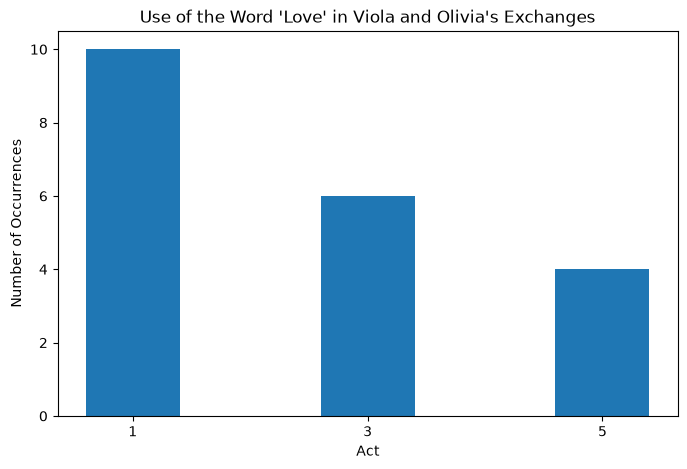

In [37]:
plt.figure(figsize=(8, 5))

plt.bar(
    love_by_act["act"],
    love_by_act["love_count"]
)

plt.title("Use of the Word 'Love' in Viola and Olivia's Exchanges")
plt.xlabel("Act")
plt.ylabel("Number of Occurrences")
plt.xticks([1, 3, 5])
plt.show()

In [38]:
for act in [1, 3, 5]:
    print(f"\n--- ACT {act}: USE OF THE WORD LOVE ---")

    act_dialogue = pair_dialogue[
        pair_dialogue["act"] == act
    ]

    for _, row in act_dialogue.iterrows():
        text = str(row["text"])

        if re.search(r"\blove\b", text, re.IGNORECASE):
            print(f"{row['speaker']}: {text}")
            print()


--- ACT 1: USE OF THE WORD LOVE ---
VIOLA: I see you what you are. You are too proud.
But if you were the devil you are fair.
My lord and master loves you. O, such love
Could be but recompensed though you were
crowned
The nonpareil of beauty.

OLIVIA: How does he love me?

VIOLA: With adorations, fertile tears,
With groans that thunder love, with sighs of fire.

OLIVIA: Your lord does know my mind. I cannot love him.
Yet I suppose him virtuous, know him noble,
Of great estate, of fresh and stainless youth;
In voices well divulged, free, learned, and valiant,
And in dimension and the shape of nature
A gracious person. But yet I cannot love him.
He might have took his answer long ago.

VIOLA: If I did love you in my master's flame,
With such a suff'ring, such a deadly life,
In your denial I would find no sense.
I would not understand it.

VIOLA: Make me a willow cabin at your gate
And call upon my soul within the house,
Write loyal cantons of contemned love
And sing them loud even in th

In [39]:
for act in [3, 5]:
    print(f"\n--- ACT {act} ---")
    for _, row in pair_dialogue[pair_dialogue["act"] == act].iterrows():
        if re.search(r"\blove\b", str(row["text"]), re.IGNORECASE):
            print(f'{row["speaker"]}: {row["text"]}\n')


--- ACT 3 ---
OLIVIA: That's a degree to love.

OLIVIA: O, what a deal of scorn looks beautiful
In the contempt and anger of his lip!
A murd'rous guilt shows not itself more soon
Than love that would seem hid. Love's night is
noon.--
Cesario, by the roses of the spring,
By maidhood, honor, truth, and everything,
I love thee so, that, maugre all thy pride,
Nor wit nor reason can my passion hide.
Do not extort thy reasons from this clause,
For that I woo, thou therefore hast no cause;
But rather reason thus with reason fetter:
Love sought is good, but given unsought is better.

VIOLA: Nothing but this: your true love for my master.


--- ACT 5 ---
VIOLA: After him I love
More than I love these eyes, more than my life,
More by all mores than e'er I shall love wife.
If I do feign, you witnesses above,
Punish my life for tainting of my love.




## Preliminary Findings

### 1. Speaking Network Across the Five Acts

The speaking network contains 18 characters and 105 unique directed speaking connections across the entire play.

The network density varies across the five acts:

| Act | Characters | Unique Speaking Connections | Network Density |
|---|---:|---:|---:|
| 1 | 11 | 32 | 29.1% |
| 2 | 11 | 34 | 30.9% |
| 3 | 13 | 46 | 29.5% |
| 4 | 7 | 20 | 47.6% |
| 5 | 12 | 45 | 34.1% |

Act 4 has the highest network density at 47.6%, meaning that a larger proportion of the possible speaking relationships between its characters occurs in this act. However, Act 4 also has the smallest number of characters, which may contribute to its higher density.

Act 3 has the greatest number of unique speaking connections, with 46. Act 5 also has a relatively high number of connections, with 45, suggesting that speaking relationships remain interconnected toward the end of the play.

### 2. Dialogue Between Viola and Olivia

The analysis identified 84 consecutive speaking turns involving Viola and Olivia across Acts 1, 3, and 5.

The dialogue demonstrates how romantic language changes throughout the play:

- **Act 1:** Viola communicates Orsino's love to Olivia while acting as his messenger.
- **Act 3:** Olivia openly confesses her love for Cesario, unaware that Cesario is Viola in disguise.
- **Act 5:** Viola expresses her love for Orsino, revealing another dimension of the romantic relationships in the play.

The word "love" appeared 20 times in the selected Viola and Olivia speaking exchanges: 10 times in Act 1, 6 times in Act 3, and 4 times in Act 5.

These findings demonstrate how disguise and mistaken identity complicate romantic communication throughout *Twelfth Night*.



## 3. Comparison with the Co-presence Network

The co-presence network and speaking network provide two different perspectives on character relationships in *Twelfth Night*.

The co-presence network examines which characters appear on stage together, showing opportunities for interaction even when characters do not directly speak to one another.

In comparison, the speaking network examines consecutive speaking turns, identifying which characters speak immediately after one another. This provides a closer look at conversational patterns throughout the play.

Comparing these networks helps distinguish between characters who simply share the same space and characters who actively participate in exchanges. However, consecutive speaking turns do not necessarily mean that one character is directly addressing the other.

Together, these approaches provide a more complete understanding of how characters interact, communicate, and connect throughout *Twelfth Night*.



## 4. Methodology and Limitations

The speaking network was created using Python with the Pandas and NetworkX libraries. The dataset contained 926 speeches from 18 characters.

To identify speaking relationships, speeches were grouped by act and scene and arranged in chronological order. Each character was connected to the character who spoke immediately afterward. The number of repeated transitions was counted and represented through weighted, directed edges.

Network density was calculated for each act by dividing the number of observed unique directed speaking connections by the total number of possible directed connections.

Dialogue analysis was also conducted by examining consecutive speaking turns between Viola and Olivia and counting selected keywords, including "love," "heart," and "beauty."

### Limitations

This method identifies which character speaks immediately after another, but it cannot confirm that the second character is being directly addressed.

The dataset does not include explicit information about intended addressees. Additionally, keyword frequency counts only identify the occurrence of particular words and cannot fully explain their meaning or emotional context.

Finally, the speaking network treats Viola as one character throughout the dataset, rather than separating her identity as Viola from her disguised identity as Cesario.
